# 11a · Set 4 sweep: 3 retrievers × 3 answerers × CoT × per-attempt shortlist × final shortlist (GPU, several sessions)

Runs the broad sweep of `Set_1__3-modality-size` on **200 questions** (the first 100 dev + 100 test of the Set 1–3 questions, 20 passages each).

| Variable | Levels |
|---|---|
| Retriever | Qwen2.5-3B, Qwen2.5-7B, Qwen2.5-32B (4-bit) |
| Answerer | Llama-3.2-3B, Llama-3.1-8B, Qwen2.5-32B (4-bit) |
| CoT | off / on (retriever and answerer together) |
| Per-attempt shortlist | paper default (no number given), "select exactly 3", "select exactly 5" |
| Final shortlist | paper default (vote merge), 2 (two most-voted), all (every passage any try picked) |

That is **162 setups** at 3 retrieval tries and 5 answer tries + fusion (1-try versions are also recorded).

**Confidence is recorded for every decision**, two ways: *stated* (the model writes a last line `Confidence: <0-100>`) and *measured*
(the probability the model gave its own output, and how much its repeated tries agree). The paper-default retrieval prompt is left
untouched, so it has measured confidence only. The report shows how well each signal tells right from wrong (Excel sheets
"Confidence" and "Calibration", chart 5).

**This notebook is resumable. Run it, and run it again, until it prints `SWEEP COMPLETE`.** Each session works through the pending
stages in order (retrieval with each retriever, then answering with each answerer, without and with CoT), stops cleanly before the time
limit, and always ends by rebuilding the tables, Excel file and charts from whatever is finished. My estimate is 5–8 GPU hours in total,
most of it the 32B; that is an estimate, not a measurement.

**Two runtimes at once:** use the two ready-made copies instead of this notebook — **11a_set4_sweep_q3-q7-l3-l8.ipynb** and
**11b_set4_sweep_q32.ipynb**. They are this notebook with `ONLY_MODELS` already set. Start 11a first; start 11b once 11a has printed its
run folder, so both use the same one. (Two tabs of the *same* notebook would overwrite each other's saved copy.)

**Where things are saved.** All sessions write into one shared run folder, because every answerer needs every retriever's shortlists
and the tables combine everything. Inside it, each session has its own labelled folder,
`sessions/<time>_<models>/` (for example `sessions/20261004-150000_q3-q7-l3-l8/` or `..._q32/`), with that session's logs, timings,
`session.json` and a snapshot of the results at its end. The raw files in `step/` are already named by model (`retrieval_q32_...`, `answers_l8_...`).

A run folder made with older prompts is never continued: the notebook skips it and starts a new one.

Output: `runs/Set_1__3-modality-size/<timestamp>_<GPU>/` with `results/summary.md`, `results/set4_results.xlsx`, `results/per_question.jsonl`,
`results/charts/`, raw outputs in `step/`. Next: **12_set4_agenttts_switching.ipynb**.

**Runtime → Change runtime type → A100 GPU.**

**This copy is preset to `ONLY_MODELS = ["q3", "q7", "l3", "l8"]`.**

In [1]:
# ==== settings ====
PROJECT_DIR = "/content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching"
EXPERIMENT  = "Set_1__3-modality-size"
SOURCE_DATA = f"{PROJECT_DIR}/data/hotpotqa_q/dev200_test200_c20_s42"   # the Set 1-3 questions
DEV_N, TEST_N = 100, 100      # the sweep uses the first 100 of each split
ONLY_MODELS = ["q3", "q7", "l3", "l8"]              # [] = every pending stage; or e.g. ["q3", "q7", "l3", "l8"] / ["q32"] to split across two runtimes
TIME_LIMIT_MIN = 55           # the session stops cleanly at this limit and keeps what is done
NEW_RUN = False               # True starts a fresh run folder instead of continuing the latest compatible one
RUN_DIR_OVERRIDE = None       # or paste a run folder to continue that one
DRY_RUN = False               # True = fake models on CPU, tests the whole notebook in ~1 min

In [2]:
import subprocess, sys, os, json, shutil, time
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv,noheader 2>/dev/null",
                     shell=True, capture_output=True, text=True).stdout.strip()
print("GPU:", gpu or "none")
if not DRY_RUN:
    assert gpu, "No GPU: Runtime -> Change runtime type -> A100 GPU (or set DRY_RUN = True)."
    if "T4" in gpu:
        raise SystemExit("This runtime has a T4, which cannot run this: the 7B model alone (15 GB) does not fit in its memory.\n"
                         "Runtime -> Change runtime type -> A100 GPU (or G4 / L4) -> Save, then run all cells again.")
    if "A100" not in gpu and "G4" not in gpu and "RTX PRO 6000" not in gpu:
        print("Note: planned for an A100 or G4; this GPU works but timings will differ.")
GPU_TAG = "cpu" if not gpu else gpu.split(",")[0].replace("NVIDIA", "").replace("Tesla", "").strip().split()[0].split("-")[0]
T_START = time.time()

GPU: NVIDIA A100-SXM4-40GB, 40960 MiB, 8.0


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
import glob
from datetime import datetime
from zoneinfo import ZoneInfo
SESSION = datetime.now(ZoneInfo("Asia/Singapore")).strftime("%Y%m%d-%H%M%S")
# which session this is: the models it is restricted to (ONLY_MODELS), or "all"
SESSION_LABEL = globals().get("SESSION_LABEL") or ("-".join(globals().get("ONLY_MODELS") or []) or "all")
import re
CODE_VERSION = re.search(r'^CODE_VERSION = "(.*)"', open(f"{PROJECT_DIR}/code/sweep.py").read(), re.M).group(1)
def run_version(d):
    """The prompt version a run folder was made with (None = empty folder)."""
    if os.path.exists(f"{d}/code_version.txt"):
        return open(f"{d}/code_version.txt").read().strip()
    return "1: before confidence tracking" if glob.glob(f"{d}/step/*.jsonl") else None
runs = [d for d in sorted(glob.glob(f"{PROJECT_DIR}/runs/{EXPERIMENT}/*")) if os.path.isdir(d) and (("_dryrun" in d) == DRY_RUN)]
skipped = [d for d in runs if run_version(d) not in (None, CODE_VERSION)]
runs = [d for d in runs if d not in skipped]
for d in skipped:
    print("Not continuing (made with older prompts, kept untouched):", os.path.basename(d))
if RUN_DIR_OVERRIDE:
    RUN_DIR = RUN_DIR_OVERRIDE
elif runs and not NEW_RUN:
    RUN_DIR = runs[-1]                      # continue the latest run of this set
else:
    RUN_DIR = f"{PROJECT_DIR}/runs/{EXPERIMENT}/{SESSION}_{GPU_TAG}" + ("_dryrun" if DRY_RUN else "")
for sub in ["logs", "code", "step", "stages"]:
    os.makedirs(f"{RUN_DIR}/{sub}", exist_ok=True)
# everything specific to this session goes in its own labelled folder inside the shared run folder
SESSION_DIR = f"{RUN_DIR}/sessions/{SESSION}_{SESSION_LABEL}"
os.makedirs(SESSION_DIR, exist_ok=True)
print("Run folder (shared by all sessions):", RUN_DIR)
print("This session's folder:", SESSION_DIR)

Not continuing (made with older prompts, kept untouched): 20261004-113202_A100
Run folder (shared by all sessions): /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100
This session's folder: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100/sessions/20261005-154320_q3-q7-l3-l8


### Questions: first 100 dev + 100 test of the Set 1–3 sample (built once)

In [5]:
DATA_DIR = f"{PROJECT_DIR}/data/hotpotqa_q/dev{DEV_N}_test{TEST_N}_c20_s42_first"
if not os.path.exists(f"{DATA_DIR}/test.json"):
    os.makedirs(DATA_DIR, exist_ok=True)
    for split, n in (("dev", DEV_N), ("test", TEST_N)):
        rows = json.load(open(f"{SOURCE_DATA}/{split}.json", encoding="utf-8"))[:n]
        json.dump(rows, open(f"{DATA_DIR}/{split}.json", "w", encoding="utf-8"), ensure_ascii=False)
    json.dump({"source": SOURCE_DATA, "dev_n": DEV_N, "test_n": TEST_N, "rule": "first n of each split"}, open(f"{DATA_DIR}/data_config.json", "w"), indent=1)
print("questions:", DATA_DIR)

questions: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/data/hotpotqa_q/dev100_test100_c20_s42_first


In [6]:
MODELS = {   # key: model, folder under models/, parameters (for compute), nominal size (for the AgentTTS budget formula)
    "q3":  {"id": "Qwen/Qwen2.5-3B-Instruct",        "dir": "Qwen2.5-3B-Instruct",        "params": 3.09e9,  "nominal": 3e9},
    "q7":  {"id": "Qwen/Qwen2.5-7B-Instruct",        "dir": "Qwen2.5-7B-Instruct",        "params": 7.62e9,  "nominal": 7e9},
    "q32": {"id": "Qwen/Qwen2.5-32B-Instruct-AWQ",   "dir": "Qwen2.5-32B-Instruct-AWQ",   "params": 32.76e9, "nominal": 32e9},
    "l3":  {"id": "meta-llama/Llama-3.2-3B-Instruct", "dir": "Llama-3.2-3B-Instruct",     "params": 3.21e9,  "nominal": 3e9},
    "l8":  {"id": "meta-llama/Llama-3.1-8B-Instruct", "dir": "Llama-3.1-8B-Instruct",     "params": 8.03e9,  "nominal": 8e9},
}
LOCAL = "/content/models"
for m in MODELS.values():
    m["path"] = f"{LOCAL}/{m['dir']}"

def ensure_local(key):
    """Copies one model from Drive to the runtime's local disk (only when a stage needs it)."""
    m = MODELS[key]
    src = f"{PROJECT_DIR}/models/{m['dir']}"
    if DRY_RUN or os.path.exists(f"{m['path']}/config.json"):
        return
    assert os.path.exists(f"{src}/config.json"), f"{src} missing - run notebook 10 first."
    idx = f"{src}/model.safetensors.index.json"
    if os.path.exists(idx):
        lost = [f for f in sorted(set(json.load(open(idx))["weight_map"].values())) if not os.path.exists(f"{src}/{f}")]
        assert not lost, f"{src} is incomplete (missing {lost}) - run notebook 10 again."
    t = time.time()
    print(f"copying {m['dir']} to local disk ...")
    shutil.copytree(src, m["path"], dirs_exist_ok=True)
    TIMES[f"copy_{key}"] = round(time.time() - t)

In [7]:
BACKEND = "mock" if DRY_RUN else "vllm"
CODE_DIR = "/content/set4code"
os.makedirs(CODE_DIR, exist_ok=True)
for f in ["ssw.py", "sweep.py"]:
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{CODE_DIR}/{f}")
    shutil.copy(f"{PROJECT_DIR}/code/{f}", f"{RUN_DIR}/code/{f}")      # keep the exact code with the results
TIMES = {}

def minutes_left():
    return max(0.0, TIME_LIMIT_MIN - (time.time() - T_START) / 60)

def run_stage(args, log_name, quiet=False):
    """Runs one sweep.py command in a fresh process; streams output here and into logs/<log_name>."""
    cmd = [sys.executable, "-u", f"{CODE_DIR}/sweep.py"] + [str(a) for a in args]
    t0 = time.time()
    with open(f"{RUN_DIR}/logs/{log_name}", "a") as log, open(f"{SESSION_DIR}/{log_name}", "a") as slog:
        log.write("\n$ " + " ".join(cmd) + "\n")
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line)
            slog.write(line)
            if quiet or any(k in line for k in ("it/s]", "s/it]", "INFO ", "(EngineCore", "WARNING ")):
                continue
            print(line, end="")
        p.wait()
    TIMES[log_name.replace(".log", "")] = TIMES.get(log_name.replace(".log", ""), 0) + round(time.time() - t0)
    json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
    if not quiet:
        print(f"--- {log_name}: exit {p.returncode}, {time.time() - t0:.0f}s, {minutes_left():.0f} min left of the limit")
    if p.returncode != 0:
        raise RuntimeError(f"stage failed - see {RUN_DIR}/logs/{log_name}")

COMMON = ["--run_dir", RUN_DIR, "--data_dir", DATA_DIR, "--models_json", f"{RUN_DIR}/models.json", "--backend", BACKEND]
json.dump(MODELS, open(f"{RUN_DIR}/models.json", "w"), indent=1)
if not os.path.exists(f"{RUN_DIR}/config.json"):
    json.dump({"experiment": EXPERIMENT, "set": "4", "data_dir": DATA_DIR, "source_data": SOURCE_DATA, "dev_n": DEV_N, "test_n": TEST_N,
               "gpu": gpu, "dry_run": DRY_RUN, "started": SESSION,
               "design": {"retrievers": ["q3", "q7", "q32"], "answerers": ["l3", "l8", "q32"], "cot": "both steps together",
                          "per_attempt_shortlist": ["silent", "3", "5"], "final_shortlist": ["vote", "top2", "all"],
                          "retrieval_tries": 3, "answer_tries": 5}}, open(f"{RUN_DIR}/config.json", "w"), indent=1)

### What is done, what is pending

In [8]:
def pending():
    run_stage(["status"] + COMMON, "status.log", quiet=True)
    st = json.load(open(f"{RUN_DIR}/sweep_status.json"))
    todo = [s for s in st["stages"] if not s["complete"] and s["total"] > 0 and s["done"] < s["total"]
            and (not ONLY_MODELS or s["model"] in ONLY_MODELS)]
    return todo, st
todo, st = pending()
print(open(f"{RUN_DIR}/logs/status.log").read().split("$")[-1].split("\n", 1)[1])

stage      model      CoT      done    total  state
retrieve   Qwen 3B    -        1200     1200  complete
retrieve   Qwen 7B    -        1200     1200  complete
retrieve   Qwen 32B   -        1200     1200  complete
answer     Llama 3B   off      2627     2627  complete
answer     Llama 3B   on       3342     3342  complete
answer     Llama 8B   off      1953     2627  PENDING
answer     Llama 8B   on          0     3342  PENDING
answer     Qwen 32B   off      2627     2627  complete
answer     Qwen 32B   on       3156     3342  PENDING
sweep not complete yet - run the notebook again to continue



In [9]:
# vLLM runs only inside the stage processes, so no runtime restart is needed (~3-5 min)
if todo and not DRY_RUN:
    !pip install -q vllm
    !pip uninstall -y -q torchaudio   # Colab's torchaudio is built for another CUDA version and breaks imports
    chk = subprocess.run([sys.executable, "-c", "from vllm import LLM; import vllm, torch; print('vLLM', vllm.__version__, '| torch', torch.__version__)"],
                         capture_output=True, text=True)
    print(chk.stdout or chk.stderr[-2000:])
    assert chk.returncode == 0, "vLLM does not import - Runtime -> Disconnect and delete runtime, then run again."
    TIMES["install_vllm"] = round(time.time() - T_START)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 320.6/320.6 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.0/426.0 kB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 49.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6

### Work through the pending stages until the time limit

In [10]:
MIN_LEFT_TO_START = 8     # do not start a new stage with less than this many minutes left
while True:
    todo, st = pending()
    if not todo:
        break
    if minutes_left() < MIN_LEFT_TO_START:
        print(f"\nTime limit close ({minutes_left():.0f} min left) - stopping here. Run this notebook again to continue.")
        break
    s = todo[0]
    key = (s["stage"], s["model"], s["cot"], s["done"])
    if key == globals().get("_last_key"):
        raise RuntimeError(f"no progress on {key[:3]} - see the log in {RUN_DIR}/logs")
    _last_key = key
    ensure_local(s["model"])
    limit = max(1.0, minutes_left() - 3)
    if s["stage"] == "retrieve":
        run_stage(["retrieve", "--model", s["model"], "--time_limit_min", limit] + COMMON, f"retrieve_{s['model']}.log")
    else:
        run_stage(["answer", "--model", s["model"], "--cot", s["cot"], "--time_limit_min", limit] + COMMON, f"answer_{s['model']}_c{s['cot']}.log")
run_stage(["status"] + COMMON, "status.log")

copying Llama-3.1-8B-Instruct to local disk ...
[07:50:29] answer l8 c0 | meta-llama/Llama-3.1-8B-Instruct | 2627 distinct shortlists, 674 to do | 5 answers + fusion











[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer CachedTokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[07:55:13]   2090/2627 shortlists answered
[07:56:03]   2214/2627 shortlists answered
[07:57:03]   2360/2627 shortlists answered
[07:58:05]   2500/2627 shortlists answered
[07:59:02]   2627/2627 shortlists answered
[07:59:03] answer l8 c0 done: 300s generation + 213s load
--- answer_l8_c0.log: exit 0, 519s, 39 min left of the limit
[07:59:10] answer l8 c1 | meta-llama/Llama-3.1-8B-Instruct | 334

### Tables, Excel workbook and charts from everything finished so far

# Set 4 sweep - 20261004-165402_A100

Questions: 200 (dev + test pooled). Main rows use 3 retrieval tries and 5 answer tries + fusion. Sweep complete: **True** (162 of 162 main setups have results).


## Best setups by accuracy

| Retriever-answerer | CoT | Per-attempt shortlist | Final shortlist | Accuracy | Compute (x cheapest) | Found both | Acc. when found | Acc. when not found |
|---|---|---|---|---|---|---|---|---|
| Qwen 32B - Qwen 32B | Y | 3 | all | 65.0% | 12.3x | 97.5% | 64.1% | 100.0% |
| Qwen 32B - Qwen 32B | Y | paper default | all | 64.5% | 11.3x | 87.5% | 64.6% | 64.0% |
| Qwen 32B - Qwen 32B | Y | 3 | paper default (vote) | 64.5% | 12.1x | 95.0% | 64.7% | 60.0% |
| Qwen 7B - Qwen 32B | Y | paper default | all | 64.0% | 5.8x | 82.5% | 65.5% | 57.1% |
| Qwen 32B - Qwen 32B | Y | 5 | all | 64.0% | 13.8x | 100.0% | 64.0% | - |
| Qwen 32B - Qwen 32B | Y | 5 | paper default (vote) | 63.5% | 13.2x | 99.0% | 63.1% | 100.0% |
| Qwen 32B - Qwen 32B | Y | 3 | 2 | 63.5% | 11.8x | 83.5% | 66.5% | 48.5% |
| Qwen 32B - Qwen 32B | N | 3 | all | 63.5% | 12.8x | 97.0% | 63.4% | 66.7% |
| Qwen 7B - Qwen 32B | Y | 3 | all | 63.0% | 6.5x | 94.0% | 63.3% | 58.3% |
| Qwen 32B - Qwen 32B | Y | paper default | paper default (vote) | 63.0% | 11.2x | 78.5% | 65.0% | 55.8% |
| Qwen 32B - Qwen 32B | Y | paper default | 2 | 63.0% | 11.3x | 84.0% | 64.3% | 56.2% |
| Qwen 7B - Qwen 32B | Y | 3 | paper default (vote) | 63.0% | 6.2x | 88.5% | 64.4% | 52.2% |

## Paper-default condition (no CoT, no number given, vote merge)

| Retriever-answerer | Accuracy | Compute (x cheapest) | Found both | Acc. when found | Acc. when not found |
|---|---|---|---|---|---|
| Qwen 3B - Llama 3B | 30.5% | 1.0x | 13.5% | 55.6% | 26.6% |
| Qwen 3B - Llama 8B | 36.5% | 2.0x | 13.5% | 48.1% | 34.7% |
| Qwen 3B - Qwen 32B | 43.5% | 4.5x | 13.5% | 66.7% | 39.9% |
| Qwen 7B - Llama 3B | 36.5% | 2.1x | 48.0% | 35.4% | 37.5% |
| Qwen 7B - Llama 8B | 41.5% | 3.0x | 48.0% | 42.7% | 40.4% |
| Qwen 7B - Qwen 32B | 52.5% | 5.4x | 48.0% | 57.3% | 48.1% |
| Qwen 32B - Llama 3B | 45.0% | 8.0x | 78.0% | 46.2% | 40.9% |
| Qwen 32B - Llama 8B | 49.0% | 8.8x | 78.0% | 48.7% | 50.0% |
| Qwen 32B - Qwen 32B | 60.5% | 11.1x | 78.0% | 59.6% | 63.6% |

## Effect of each variable (main setups)

| Variable | Level | Mean accuracy | Best accuracy | Mean found both | Mean compute |
|---|---|---|---|---|---|
| Retriever | Qwen 3B | 42.5% | 59.5% | 37.9% | 2.9x |
| Retriever | Qwen 7B | 48.6% | 64.0% | 71.6% | 3.9x |
| Retriever | Qwen 32B | 52.8% | 65.0% | 86.9% | 10.4x |
| Answerer | Llama 3B | 39.4% | 46.0% | 65.5% | 4.1x |
| Answerer | Llama 8B | 47.7% | 57.0% | 65.5% | 5.3x |
| Answerer | Qwen 32B | 56.8% | 65.0% | 65.5% | 7.9x |
| CoT | N | 45.3% | 63.5% | 57.4% | 5.7x |
| CoT | Y | 50.6% | 65.0% | 73.5% | 5.8x |
| Per-attempt shortlist | paper default | 47.6% | 64.5% | 58.2% | 5.3x |
| Per-attempt shortlist | 3 | 48.6% | 65.0% | 68.1% | 5.7x |
| Per-attempt shortlist | 5 | 47.7% | 64.0% | 70.1% | 6.3x |
| Final shortlist | paper default (vote) | 48.1% | 64.5% | 66.1% | 5.8x |
| Final shortlist | 2 | 46.1% | 63.5% | 54.4% | 5.6x |
| Final shortlist | all | 49.6% | 65.0% | 75.8% | 5.9x |

## Confidence: does it tell right from wrong?

Stated = the 'Confidence: N' the model wrote. Separation 0.5 = no better than chance, 1.0 = perfect. The paper-default retrieval prompt is left untouched, so it has no stated confidence.

| Step | Model | CoT | Signal | Mean confidence | Share correct | Overconfidence | Separation | Correct when above median | at or below |
|---|---|---|---|---|---|---|---|---|---|
| answer | Llama 3B | N | stated by the model (final answer) | 0.85 | 36.0% | +0.49 | 0.66 | 49% | 26% |
| answer | Llama 3B | N | stated by the model (mean of the 5 drafts) | 0.84 | 36.0% | +0.48 | 0.62 | - | - |
| answer | Llama 3B | N | token probability (final answer) | 0.78 | 36.0% | - | 0.48 | 35% | 37% |
| answer | Llama 3B | N | agreement of the 5 answers | 0.68 | 36.0% | - | 0.70 | 51% | 22% |
| answer | Llama 3B | Y | stated by the model (final answer) | 0.90 | 39.6% | +0.50 | 0.63 | - | - |
| answer | Llama 3B | Y | stated by the model (mean of the 5 drafts) | 0.89 | 39.6% | +0.50 | 0.60 | - | - |
| answer | Llama 3B | Y | token probability (final answer) | 0.82 | 39.6% | - | 0.53 | 42% | 37% |
| answer | Llama 3B | Y | agreement of the 5 answers | 0.61 | 39.6% | - | 0.74 | 62% | 26% |
| answer | Llama 8B | N | stated by the model (final answer) | 0.89 | 43.5% | +0.43 | 0.69 | 71% | 39% |
| answer | Llama 8B | N | stated by the model (mean of the 5 drafts) | 0.85 | 43.5% | +0.42 | 0.72 | 60% | 28% |
| answer | Llama 8B | N | token probability (final answer) | 0.82 | 43.5% | - | 0.46 | 41% | 46% |
| answer | Llama 8B | N | agreement of the 5 answers | 0.70 | 43.5% | - | 0.78 | 71% | 28% |
| answer | Llama 8B | Y | stated by the model (final answer) | 0.91 | 47.7% | +0.39 | 0.65 | 70% | 45% |
| answer | Llama 8B | Y | stated by the model (mean of the 5 drafts) | 0.90 | 47.7% | +0.42 | 0.69 | 64% | 33% |
| answer | Llama 8B | Y | token probability (final answer) | 0.84 | 47.7% | - | 0.48 | 47% | 48% |
| answer | Llama 8B | Y | agreement of the 5 answers | 0.70 | 47.7% | - | 0.76 | 72% | 35% |
| answer | Qwen 32B | N | stated by the model (final answer) | 0.95 | 51.7% | +0.43 | 0.69 | - | - |
| answer | Qwen 32B | N | stated by the model (mean of the 5 drafts) | 0.87 | 51.7% | +0.35 | 0.71 | - | - |
| answer | Qwen 32B | N | token probability (final answer) | 0.84 | 51.7% | - | 0.62 | 60% | 43% |
| answer | Qwen 32B | N | agreement of the 5 answers | 0.84 | 51.7% | - | 0.75 | - | - |
| answer | Qwen 32B | Y | stated by the model (final answer) | 0.97 | 56.5% | +0.40 | 0.65 | - | - |
| answer | Qwen 32B | Y | stated by the model (mean of the 5 drafts) | 0.93 | 56.5% | +0.36 | 0.68 | - | - |
| answer | Qwen 32B | Y | token probability (final answer) | 0.85 | 56.5% | - | 0.60 | 64% | 49% |
| answer | Qwen 32B | Y | agreement of the 5 answers | 0.87 | 56.5% | - | 0.73 | - | - |
| retrieval | Qwen 3B | N | stated by the model (per try) | 0.97 | 21.4% | +0.72 | 0.50 | - | - |
| retrieval | Qwen 3B | N | token probability (per try) | 0.95 | 21.4% | - | 0.45 | 18% | 25% |
| retrieval | Qwen 3B | N | agreement of the 3 tries | 0.65 | 22.7% | - | 0.52 | 23% | 22% |
| retrieval | Qwen 3B | Y | stated by the model (per try) | 0.96 | 39.6% | +0.56 | 0.52 | - | - |
| retrieval | Qwen 3B | Y | token probability (per try) | 0.78 | 39.6% | - | 0.55 | 44% | 35% |
| retrieval | Qwen 3B | Y | agreement of the 3 tries | 0.47 | 46.5% | - | 0.58 | 51% | 43% |
| retrieval | Qwen 7B | N | stated by the model (per try) | 0.92 | 58.4% | +0.28 | 0.44 | 54% | 71% |
| retrieval | Qwen 7B | N | token probability (per try) | 0.97 | 58.4% | - | 0.49 | 58% | 59% |
| retrieval | Qwen 7B | N | agreement of the 3 tries | 0.73 | 60.7% | - | 0.46 | 54% | 65% |
| retrieval | Qwen 7B | Y | stated by the model (per try) | 0.94 | 81.0% | +0.13 | 0.49 | 76% | 84% |
| retrieval | Qwen 7B | Y | token probability (per try) | 0.85 | 81.0% | - | 0.57 | 84% | 78% |
| retrieval | Qwen 7B | Y | agreement of the 3 tries | 0.69 | 85.2% | - | 0.62 | 90% | 82% |
| retrieval | Qwen 32B | N | stated by the model (per try) | 0.87 | 90.6% | -0.09 | 0.40 | 96% | 97% |
| retrieval | Qwen 32B | N | token probability (per try) | 0.98 | 90.6% | - | 0.44 | 89% | 92% |
| retrieval | Qwen 32B | N | agreement of the 3 tries | 0.83 | 90.8% | - | 0.45 | - | - |
| retrieval | Qwen 32B | Y | stated by the model (per try) | 0.93 | 90.3% | +0.03 | 0.40 | - | - |
| retrieval | Qwen 32B | Y | token probability (per try) | 0.68 | 90.3% | - | 0.42 | 87% | 93% |
| retrieval | Qwen 32B | Y | agreement of the 3 tries | 0.80 | 90.8% | - | 0.56 | 92% | 90% |

Full tables: `results/set4_results.xlsx`. Per-question rows: `results/per_question.jsonl`. Charts: `results/charts/`.


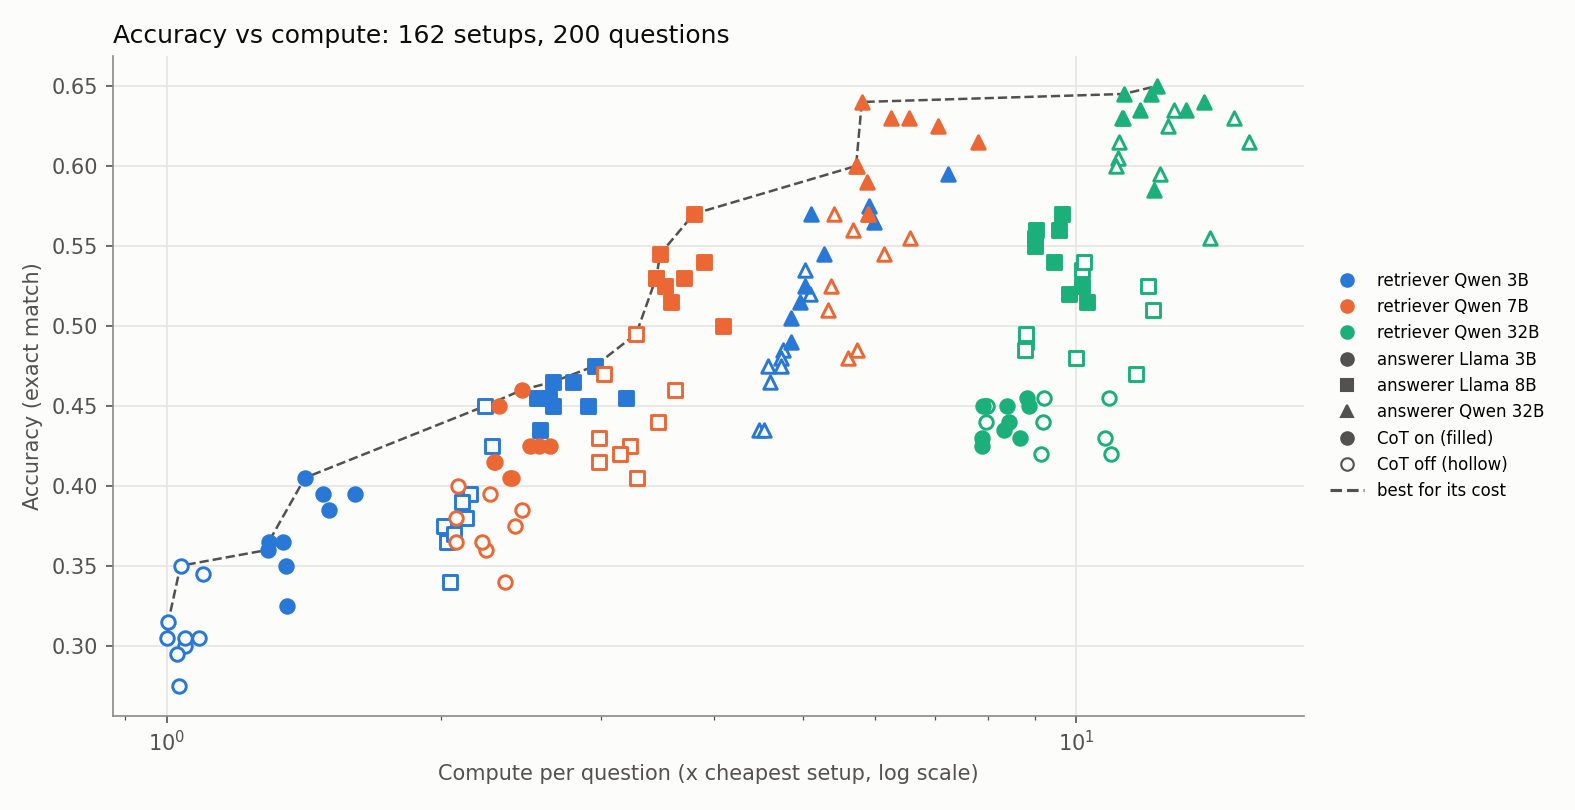

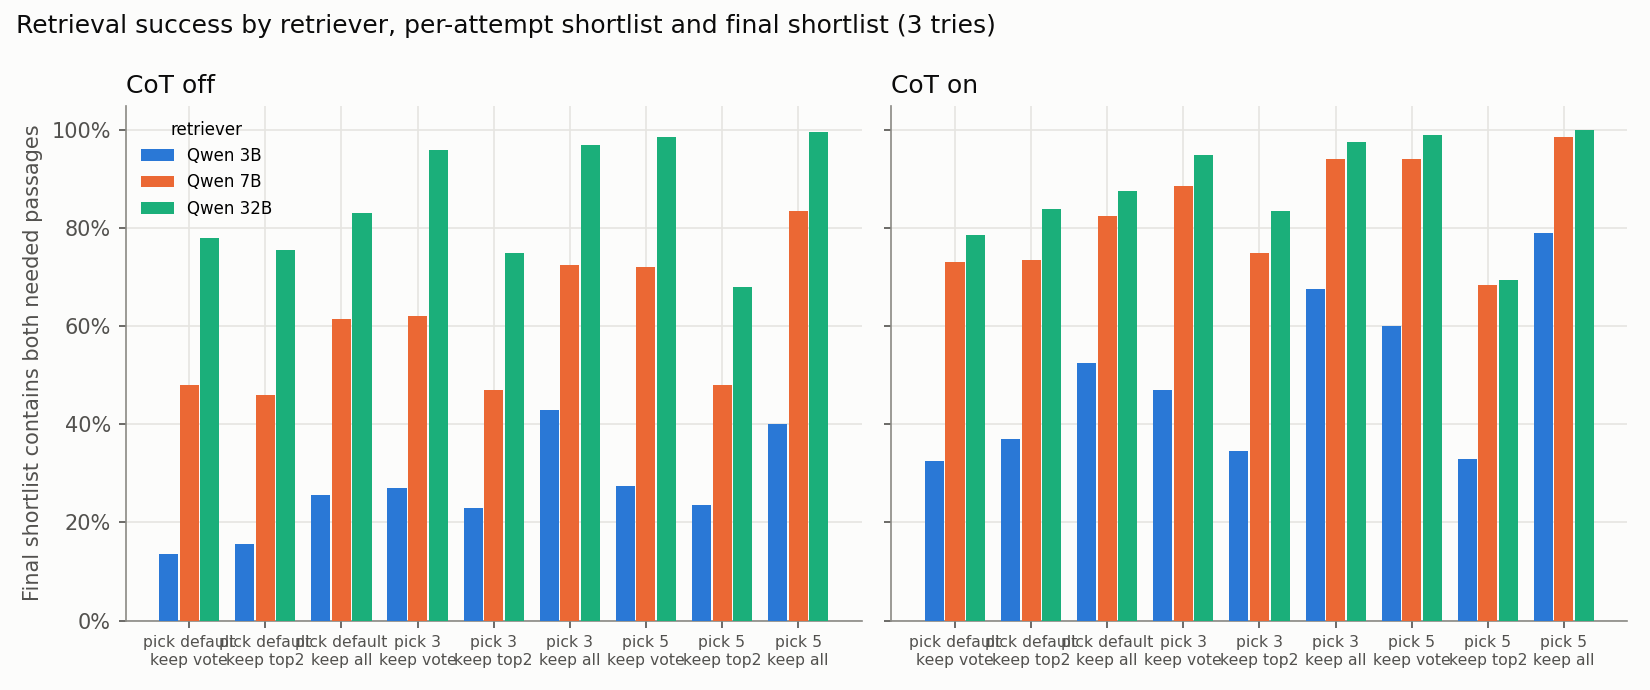

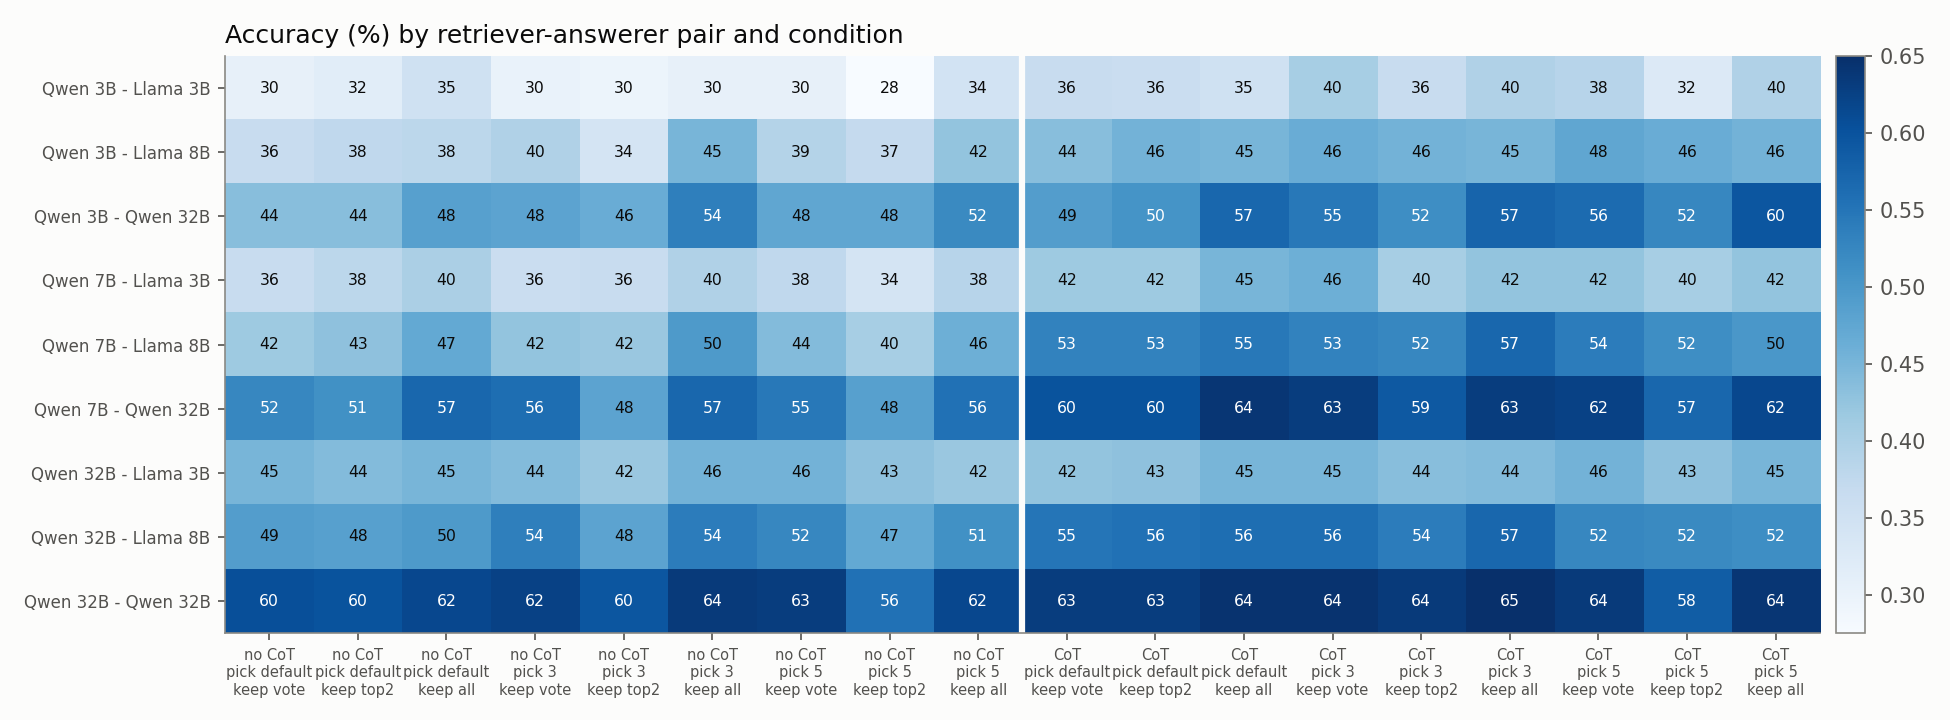

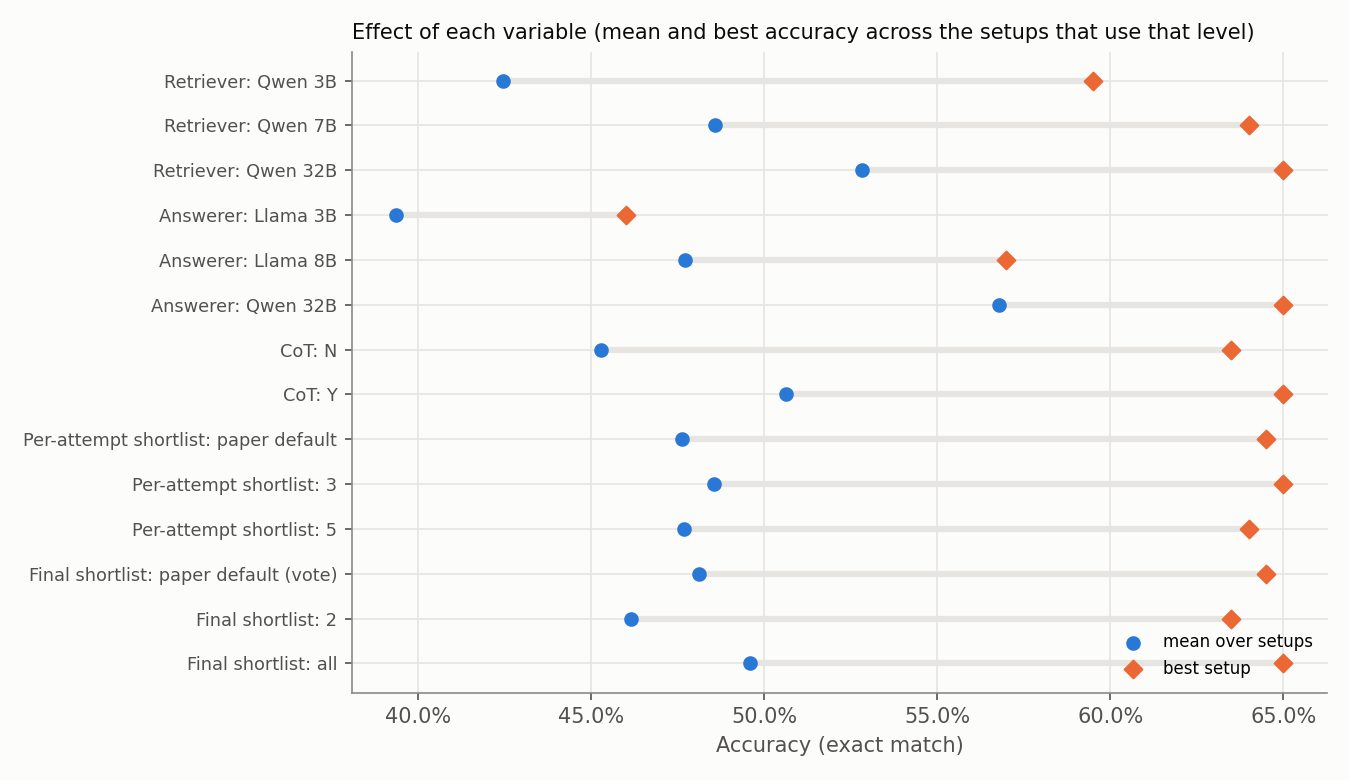

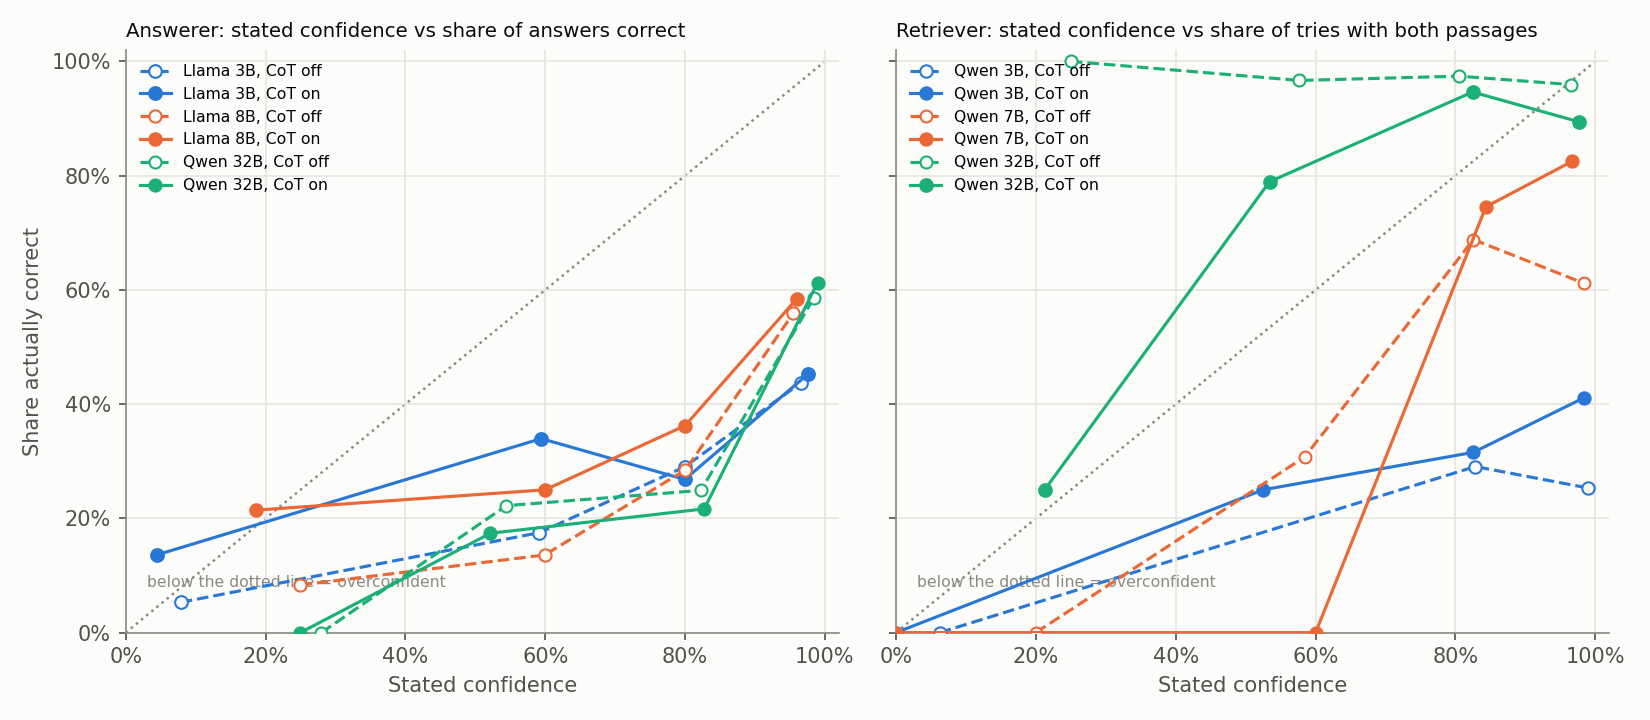

Excel workbook: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100/results/set4_results.xlsx
Wall-clock this session (s): {'status': 24, 'install_vllm': 258, 'copy_l8': 195, 'answer_l8_c0': 519, 'answer_l8_c1': 2021, 'report': 40, 'total_session': 3043}
Session record: /content/drive/MyDrive/0_EngD_assignments/0_Small_Big_Model_Switching/runs/Set_1__3-modality-size/20261004-165402_A100/sessions/20261005-154320_q3-q7-l3-l8

SWEEP COMPLETE - next: 12_set4_agenttts_switching.ipynb


In [11]:
run_stage(["report"] + COMMON, "report.log", quiet=True)
from IPython.display import Image, Markdown, display
if os.path.exists(f"{RUN_DIR}/results/summary.md"):
    display(Markdown(open(f"{RUN_DIR}/results/summary.md").read()))
    for f in sorted(glob.glob(f"{RUN_DIR}/results/charts/*.png")):
        display(Image(f))
    print("Excel workbook:", f"{RUN_DIR}/results/set4_results.xlsx")
TIMES["total_session"] = round(time.time() - T_START)
json.dump(TIMES, open(f"{SESSION_DIR}/stage_times.json", "w"), indent=1)
print("Wall-clock this session (s):", TIMES)

# ---- record of this session: which models it was for, what it ran, and a snapshot of the results as they stood at its end ----
import shutil
ran = [k for k in TIMES if k.startswith(("retrieve_", "answer_"))]
json.dump({"session": SESSION, "label": SESSION_LABEL, "only_models": ONLY_MODELS or "all", "gpu": gpu, "code_version": CODE_VERSION,
           "stages_run": ran, "seconds": TIMES, "run_dir": RUN_DIR,
           "sweep_complete": json.load(open(f"{RUN_DIR}/sweep_status.json"))["complete"]}, open(f"{SESSION_DIR}/session.json", "w"), indent=1)
os.makedirs(f"{SESSION_DIR}/results_snapshot", exist_ok=True)
for f in ["summary.md", "set4_results.xlsx", "setups.jsonl"]:
    if os.path.exists(f"{RUN_DIR}/results/{f}"):
        shutil.copy(f"{RUN_DIR}/results/{f}", f"{SESSION_DIR}/results_snapshot/{f}")
if os.path.isdir(f"{RUN_DIR}/results/charts"):
    shutil.copytree(f"{RUN_DIR}/results/charts", f"{SESSION_DIR}/results_snapshot/charts", dirs_exist_ok=True)
with open(f"{SESSION_DIR}/README.md", "w") as f:
    f.write(f"# Session {SESSION} - ONLY_MODELS = {ONLY_MODELS or 'all'}\n\nGPU: {gpu}\n\nStages run in this session: {', '.join(ran) or 'none'}\n\n"
            f"Seconds: {TIMES}\n\n`results_snapshot/` = the tables and charts as they stood when this session ended "
            f"(built from everything finished in the shared run folder at that time, not only this session's models).\n")
print("Session record:", SESSION_DIR)
print("\nSWEEP COMPLETE - next: 12_set4_agenttts_switching.ipynb" if json.load(open(f"{RUN_DIR}/sweep_status.json"))["complete"]
      else "\nNOT COMPLETE YET - run this notebook again to continue.")